Import the modules that will be used.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

## Exercise 11.1

Determine by counting the number of mathematical operations the complexity of:

1. Dot product between two vectors
1. Matrix-vector product
1. Matrix-matrix product

for vectors of length $n$ and matrices of size $n \times n$.

This is a reasoning exercise - you do not need to write a program. Express your answers in text and using LaTeX in a Markdown cell.


### Optional

Test the complexity experimentally with your own functions for performing the operations, and
with the NumPy 'vectorised' equivalents.

### Solution

1. $O(n)$
2. $O(n^2)$
3. $O(n^3)$

## Exercise 11.2

For the recursive factorial algorithm in Activity 04, determine the algorithmic complexity by inspecting your implementation of the algorithm. Test this against numerical experiments.

### Solution

Recall the factorial algorithm from Activity 04.4:

In [2]:
def factorial(n):
    if n == 0:
        return 1
    else:
        return factorial(n - 1)*n

The function calls itself (recursively) $n$ times, hence it has complexity $O(n)$. We test this below and plot
the times.

/tmp/ipykernel_3617/1108553842.py:5: RuntimeWarning: overflow encountered in scalar multiply
  return factorial(n - 1)*n


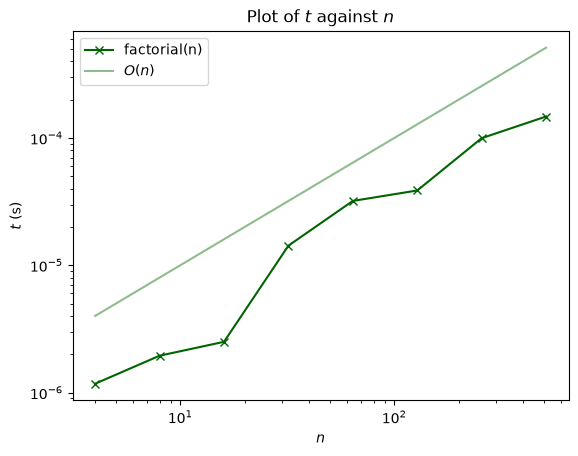

In [3]:
# Create array of problem sizes we want to test (powers of 2)
N = 2**np.arange(2, 10)

times = []
for n in N:
    t = %timeit -q -n2 -r2 -o factorial(n)
    times.append(t.best)

plt.loglog(N, times, marker='x', color='darkgreen', label='factorial(n)')
plt.loglog(N, 1e-6*N, color='darkseagreen', label='$O(n)$')

plt.xlabel('$n$')
plt.ylabel('$t$ (s)')
plt.legend(loc=0)
plt.title("Plot of $t$ against $n$")
plt.show()

## Exercise 11.3

Determine experimentally the complexity of computing the determinant of a matrix. You can generate an $n \times n$ matrix using:

In [4]:
n = 100
A = np.random.rand(n, n)

and the determinant can be computed by:

In [5]:
det = np.linalg.slogdet(A)

Be sure that you test for sufficiently large $n$ to get into the 'large' $n$ regime.

### Solution

Time computation of determinant:

In [6]:
# Create array of problem sizes we want to test (powers of 2)
N = 2**np.arange(2, 10)

times = []
for n in N:
    A = np.random.rand(n, n)
    t = %timeit -q -n2 -r2 -o np.linalg.det(A)
    times.append(t.best)

Plot result:

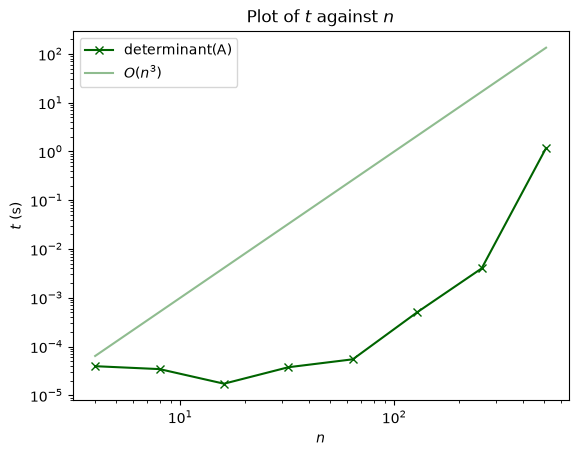

In [7]:
plt.loglog(N, times, marker='x', color='darkgreen', label='determinant(A)')
plt.loglog(N, 1e-6*N**3, color='darkseagreen', label='$O(n^3)$')

plt.xlabel('$n$')
plt.ylabel('$t$ (s)')
plt.legend(loc=0)
plt.title("Plot of $t$ against $n$")
plt.show()